# 6.1 Autoencoder
An autoencoder is a neural network that learns to compress data into a low-dimensional “code” (latent space) via an encoder, and then reconstruct the original data from that code via a decoder.  ￼
During training it minimizes reconstruction error, forcing the network to capture only the essential features — useful for tasks like dimensionality reduction, denoising, or feature learning.


![autoencoder](./docs/autoencoder.jpg)

In [ ]:
# %pip install torch torchvision tqdm ipywidgets

In [2]:
import os
import torch
import ipywidgets as widgets
import matplotlib.pyplot as plt

from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from tqdm import tqdm

## **TASK: Autoencoder Training and Latent Space Visualization**

In this task, you will train an autoencoder on the MNIST dataset and analyze its latent space representation.

Steps:
1. Define and initialize an autoencoder model using PyTorch.
2. Train the autoencoder on MNIST images, monitoring the loss over epochs with a progress bar (tqdm).
3. Save the trained model for later use.
4. Reload the model and use interactive sliders to visualize how changes in the 2D latent space affect the reconstructed images.
5. Project the test set into the latent space and create a scatter plot to visualize the distribution of digit classes in the 2D latent space.

This workflow demonstrates how autoencoders can compress high-dimensional data into a low-dimensional latent space, and how this space can be explored and visualized.

In [3]:
# Load MNIST dataset
transform = transforms.Compose([transforms.ToTensor()])
train_data = datasets.MNIST(root='./data/', train=True, download=True, transform=transform)
train_loader = DataLoader(train_data, batch_size=128, shuffle=True)

In [4]:
# 1. Define the Autoencoder model
class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28*28, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 2)
        )
        self.decoder = nn.Sequential(
            nn.Linear(2, 128),
            nn.ReLU(),
            nn.Linear(128, 256),
            nn.ReLU(),
            nn.Linear(256, 28*28),
            nn.Sigmoid()
        )
    def forward(self, x):
        z = self.encoder(x)
        out = self.decoder(z).view(-1,1,28,28)
        return out, z

In [5]:
model = Autoencoder().to('cpu')
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

In [6]:
# 2. Training the Autoencoder on MNIST dataset
EPOCHS = 10

for epoch in tqdm(range(EPOCHS), desc=f"Epochs"):
    total = 0
    
    # Iterate over data loader
    for x, _ in train_loader:
        
        # Ensure data is on the same device as model
        x = x.to('cpu')
        
        # Zero gradients to prevent accumulation from previous steps
        opt.zero_grad()
        
        # Forward pass
        out, _ = model(x)
        
        # Compute loss and backpropagate
        loss = loss_fn(out, x)
        loss.backward()
        
        # Update model parameters
        opt.step()
        
        # Accumulate loss for reporting
        total += loss.item()
    print(f"Epoch {epoch+1}, loss={total/len(train_loader):.4f}")


Epochs:  10%|█         | 1/10 [00:02<00:22,  2.47s/it]

Epoch 1, loss=0.0604


Epochs:  20%|██        | 2/10 [00:04<00:19,  2.41s/it]

Epoch 2, loss=0.0465


Epochs:  30%|███       | 3/10 [00:07<00:16,  2.37s/it]

...

Epoch 8, loss=0.0384


Epochs:  90%|█████████ | 9/10 [00:21<00:02,  2.45s/it]

Epoch 9, loss=0.0381


Epochs: 100%|██████████| 10/10 [00:24<00:00,  2.42s/it]

Epoch 10, loss=0.0377


In [7]:
# 3. Save the trained model
torch.save(model.state_dict(), "./assets/autoencoder.pt")
print(f'Model saved to autoencoder.pt with size {os.path.getsize("./assets/autoencoder.pt")} bytes')

Model saved to autoencoder.pt with size 1881031 bytes


In [8]:
# 4. Reload Model and analyse prediction with interactive slider
model = Autoencoder().to('cpu')
model.load_state_dict(torch.load("./assets/autoencoder.pt", map_location='cpu'))
model.eval()

z1 = widgets.FloatSlider(min=-30, max=30, step=0.1, value=0)
z2 = widgets.FloatSlider(min=-30, max=30, step=0.1, value=0)

def render(z1, z2):
    with torch.no_grad():
        z = torch.tensor([[z1, z2]], dtype=torch.float32).to('cpu')
        img = model.decoder(z).view(28,28).cpu()
        plt.imshow(img, cmap='gray')
        plt.show()

ui = widgets.VBox([z1, z2])
out = widgets.interactive_output(render, {'z1': z1, 'z2': z2})
display(ui, out)

Output()

In [9]:
# 5. Visualize the 2D latent space of the test dataset
test_data = datasets.MNIST(root='./data/', train=False, download=True, transform=transform)
test_loader = DataLoader(test_data, batch_size=512, shuffle=False)

model.eval()

latents = []
labels = []

In [10]:
with torch.no_grad():
    for x, y in test_loader:
        x = x.to('cpu')
        _, z = model(x)
        latents.append(z.cpu())
        labels.append(y)

latents = torch.cat(latents)
labels = torch.cat(labels)

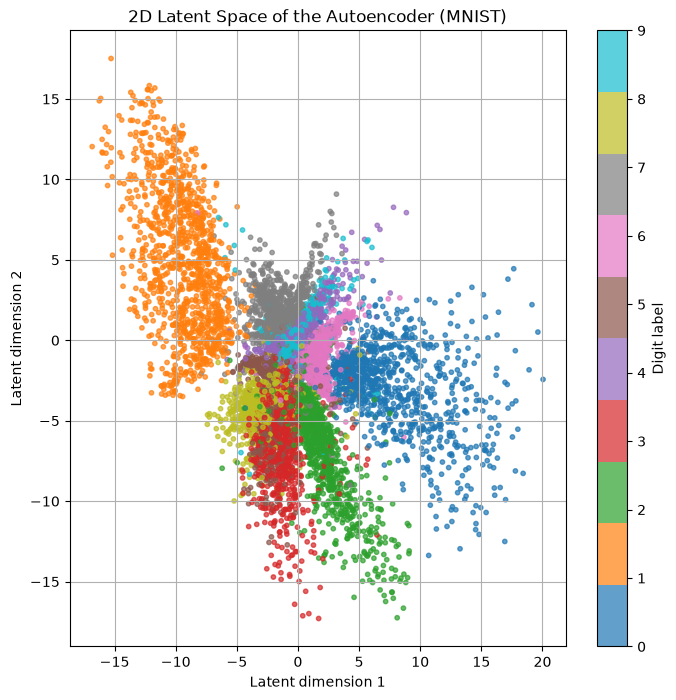

In [11]:
# Scatter plot
plt.figure(figsize=(8, 8))
scatter = plt.scatter(
    latents[:, 0], 
    latents[:, 1], 
    c=labels, 
    cmap='tab10', 
    alpha=0.7, 
    s=10
)

plt.colorbar(scatter, ticks=range(10), label="Digit label")
plt.title("2D Latent Space of the Autoencoder (MNIST)")
plt.xlabel("Latent dimension 1")
plt.ylabel("Latent dimension 2")
plt.grid(True)
plt.show()